Первые пять элемнтов выборки: [27, 18, 40, 27, 41]..... ----> 35.096774193548384
Первые пять элемнтов выборки: [46, 19, 24, 38, 59]..... ----> 38.41935483870968
Первые пять элемнтов выборки: [38, 42, 23, 18, 48]..... ----> 34.145161290322584
Первые пять элемнтов выборки: [36, 45, 23, 33, 38]..... ----> 35.11290322580645
Первые пять элемнтов выборки: [33, 45, 21, 25, 64]..... ----> 34.435483870967744
Первые пять элемнтов выборки: [25, 40, 24, 19, 61]..... ----> 36.854838709677416
Первые пять элемнтов выборки: [45, 60, 49, 26, 19]..... ----> 35.725806451612904
Первые пять элемнтов выборки: [29, 19, 46, 25, 31]..... ----> 34.645161290322584
Первые пять элемнтов выборки: [29, 39, 43, 28, 38]..... ----> 38.354838709677416
Первые пять элемнтов выборки: [20, 34, 49, 43, 65]..... ----> 35.96774193548387
Первые пять элемнтов выборки: [57, 36, 21, 18, 44]..... ----> 36.04838709677419
Первые пять элемнтов выборки: [50, 28, 23, 39, 31]..... ----> 33.693548387096776
Первые пять элемнтов выборки: [4

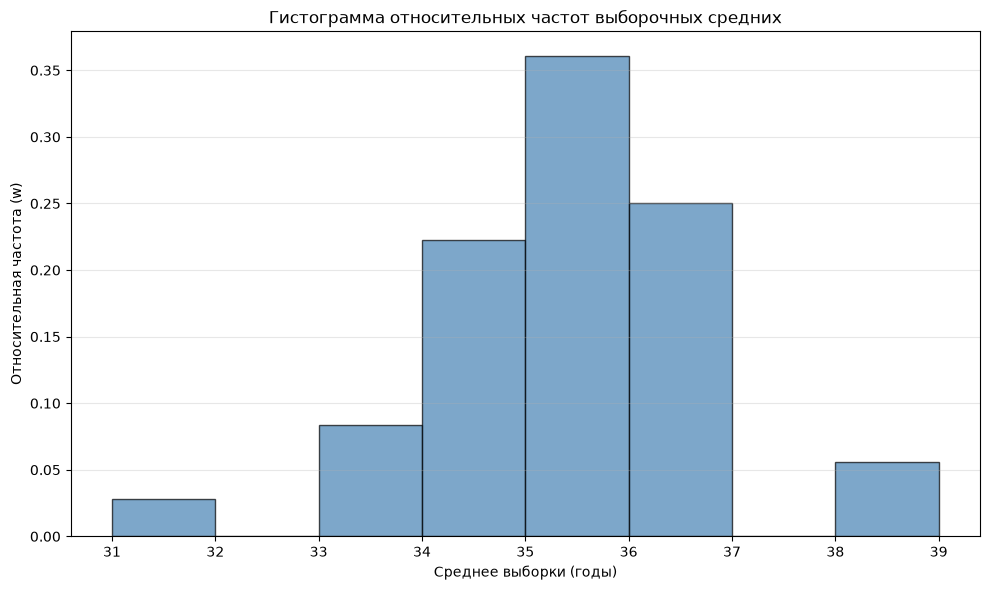

In [34]:
#Библиотеки
from math import ceil
from pathlib import Path # Библиотека для работы с файлами и их адресами
from collections import Counter
from scipy.stats import norm #
import math # Библиотка для математический действий
import matplotlib.pyplot as plt # библиотека для рисования графико и диаграмм в в питоне.
from random import randint

def calculate_n (d):# Высчитываем объем группы для одной выборки
   y = 0.95 # надежность из условия из условия
   b = 3 # точность оценки математического ожидания из условия
   f_t = (y+1) / 2
   t = norm.ppf(f_t) 
   n = t**2 * d**2 / b**2
   n = int(math.ceil(n))  # округляем в большую сторону чтобы n было целым числом
   return n

def lets_make_a_groops (numbers, n, N): # создаем 36 групп по полученному n (объему выборки) из функции calculate_n
    k = 36 # количество групп из условия
    all_selections = [] # список со списками выборок, 36 штук
    mid = [] # среднии для каждой выборки
    for selection in range(k):
        one = [] # одна выборка
        sum_ = 0 # сумма для подсчета среднего
        for num in range(n):
            i = randint(0, N - 1) # выбор случайных чисел по условию репрезитативности выборки
            one.append(numbers[i]) # добавление элемента выборку
            sum_ += numbers[i]
        mid.append(sum_ / len(one)) # подсчет средней
        all_selections.append(one) # добавление одной выборки в список выборок
        print(f"Первые пять элемнтов выборки: {one[:5]}.....", "---->", sum_ / len(one))
    return all_selections, mid # возвращает картеж со списком списокв выборок и списком средних

def gistogram_builder (intervals, w): # функция для построения гистограммы
    fig, ax = plt.subplots(figsize=(10, 6))
    centers = [(interval[0] + interval[1]) / 2 for interval in intervals]
    ax.bar(centers, w, width=1.0, color='steelblue', edgecolor='black', alpha=0.7)
    ax.set_title("Гистограмма относительных частот выборочных средних")
    ax.set_xlabel("Среднее выборки (годы)")
    ax.set_ylabel("Относительная частота (w)")
    ax.grid(True, alpha=0.3, axis='y')
    plt.tight_layout()
    plt.show()

def inteval_raw_building (mid, l_mid): # функция для построения и выведения интервального ряда
    sn = sorted(mid)
    left = math.floor(min(mid)) #левая граница – округленное вниз минимальное значение выборочной средней
    right = math.ceil(max(mid))  # правая граница – округленное вверх максимальное значение выборочной средней
    intervals = [] # список интервалов
    for edge in range(left, right):
        one = [edge, edge + 1] # создание одного интервала
        intervals.append(one) # добавление интервала
    chastots = [] # список частот
    for interval in intervals: # вычисление частот попадания в интервал
        k = 0
        for val in sn:
            if sn.index(val) == len(sn) - 1:
                if interval[0] <= val <= interval[1]:
                    k += 1
            else:
                 if interval[0] <= val < interval[1]:
                    k += 1
        chastots.append(k)
    w = [(i / l_mid) for i in chastots] # список относительных частот
    print(f"| {'Интервал':>12} || {'Частота':>8} || {'Относительная частота':>22}|")
    k = 0
    for interval in intervals: # вывод интервалов, частот, относительных частот
        interv = f"[{interval[0]}, {interval[1]})"
        if intervals.index(interval) == len(intervals) - 1:
            interv = f"[{interval[0]}, {interval[1]}]"

        print(f"| {interv:>12} || {chastots[k]:>8} || {w[k]:>13}|")
        k += 1
    gistogram_builder(intervals, w)


fp = Path("./Москва_2021.txt") 
if fp.exists():
    with open(fp, "r", encoding="utf-8") as f: # Открыть и прочитать файл, на любом языке с переменной файла f
        numbers = sorted([int(line.strip()) for line in f if line.strip()])
    sn = sorted(set(numbers))
    N = 0 # Сумма частот
    x_midl = 0 # Среднее +
    for i in sn:
        n = numbers.count(i) # кол. элемента
        x_midl += i * n # высчитываем сумму среднего, но пока без деления на сумму частот
        N+= n
    x_midl /= N
    D = 0
    for i in sn:
        D += (i - x_midl)**2 * numbers.count(i)
    D = D / N # Дисперсия
    d = math.sqrt(D) # среднее квадратичное отклонение
    n = calculate_n(d) # высчитываем объем
    all_selections, mid = lets_make_a_groops(numbers, n, N) # получаем список списков групп + список средних
    inteval_raw_building(mid, len(mid)) # строим интервальный ряд
else:
    print("Скачайте или создайте файл Москва_2021.txt")